# Entrega 3 · Modelado — ¿Cuántas réplicas va a tener un terremoto?

Ciencia de Datos · UTN FRM · 2026

**Pregunta del proyecto:** Cuando ocurre un sismo, ¿cuántas réplicas podemos esperar?



# Qué cambió desde la Entrega 2

**La pregunta no cambió:** cuántas réplicas deja un sismo principal (`n_aftershocks`).
Cambiaron los datos, cuándo se considera que ocurre la predicción y la forma de la respuesta.

| | Entrega 2 | Entrega 3 |
|---|---|---|
| Región | Andes centrales (una caja) | 5 regiones de subducción: México–CA, Andes, Japón, Sumatra–Java, Filipinas |
| Período | 2016–2026 | 2003–2025 |
| Secuencias | 1.978 | 21.292 |
| Sismo principal | `largest`: el mayor de la secuencia | `root`: el que la abre |
| Umbral de detección | uno solo (M 4,5) | uno por región (`region_mc`, de 4,2 a 4,7) |
| Columnas nuevas | — | `region`, `region_mc`, `n_prior_30d` |
| Respuesta | conteo exacto | intervalo: 0 · 1–2 · 3–10 · 11+ |

## Por qué cada cambio

- **Más regiones.** En la E2 la H3 y la H4 quedaron con 19 sismos someros contra 22 profundos
  de magnitud mayor a 6, y no alcanzaba para concluir nada. Ahora hay 431 sismos de M6–7
  y 59 de M7 o más.
- **`root` en vez de `largest`.** Era el pendiente principal de la E2: el mayor de la
  secuencia sólo se conoce cuando la secuencia terminó. Ya habíamos medido el costo:
  con `root`, el η² de la magnitud bajaba de 0,377 a 0,145. Elegimos la versión más honesta
  aunque sea más difícil. Como consecuencia, `n_foreshocks` queda siempre en 0 y sale del dataset.
- **Umbral por región.** Juntar regiones trae un problema nuevo: México detecta desde M4,2
  y Filipinas desde M4,7. Por eso aparece `mag_sobre_mc` (ver más abajo).
- **Intervalos en vez de conteo.** En la E2 vimos 93 % de ceros y una varianza 9 veces la media.
  Un modelo que dice siempre "cero" acierta casi todo, así que la métrica pasa a ser f1 macro
  y la respuesta, un intervalo.

## Lo que nos marcaron / dejamos pendiente en la Entrega 2

| Pendiente | Estado |
|---|---|
| Clusters de más de 1.500 km | Resuelto en el pipeline con un tope de distancia padre–hijo (`rmax=gk3`) |
| `largest` contra `root` | Resuelto: usamos `root` |
| Actividad previa sin fuga | Agregada como `n_prior_30d`; se probó y no mejora por más que el desvío |
| Métrica que no sea accuracy | f1 macro, con el piso medido |
| Sobredispersión | Probamos Poisson y binomial negativa; la conclusión está en la comparación de modelos |
| Ventana de tiempo del objetivo | Parcial: comprobamos que los años recientes no tienen menos réplicas por falta de tiempo, pero `n_aftershocks` sigue sin límite de tiempo |

# Dataset

In [ ]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

SEMILLA = 42
np.random.seed(SEMILLA)


ARCHIVO  = "clusters_combined_5regions_rmax=gk3_mainshock=root_seed=1.csv"
ID_DRIVE = "1O_Rkxc2x9mPiHnE6jgAe7U8ny-10-1vA"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO


In [ ]:
df = pd.read_csv(ARCHIVO, low_memory=False)
df["mainshock_time"] = pd.to_datetime(df["mainshock_time"])
# ordenamos por fecha: la partición
df = df.sort_values("mainshock_time").reset_index(drop=True)
df.shape

(21292, 27)

## Qué predecimos: `n_aftershocks`

In [ ]:
y_todo = df["n_aftershocks"]
pd.Series({"secuencias": len(df),
           "sin ninguna réplica (%)": round((y_todo == 0).mean() * 100, 1),
           "con 1 a 10 réplicas (%)": round(y_todo.between(1, 10).mean() * 100, 1),
           "con más de 10 (%)": round((y_todo > 10).mean() * 100, 1),
           "media": round(y_todo.mean(), 2),
           "mediana": y_todo.median(),
           "máximo": y_todo.max()})

,0
secuencias,"21,292.000"
sin ninguna réplica (%),88.100
con 1 a 10 réplicas (%),11.300
con más de 10 (%),0.700
media,0.760
mediana,0.000
máximo,"2,544.000"


Casi el 90% de las secuencias no presenta ninguna réplica, mientras que un porcentaje reducido tiene entre 1 y 10, y solo el 0,7% supera las 10 réplicas. La media de 0,76 indica que, al sumar el número de réplicas de todas las secuencias y dividirlo por el total de secuencias analizadas, se obtiene un valor inferior a una réplica por secuencia. Sin embargo, este valor está influido por algunos casos extremos, ya que el máximo alcanza las 2.544 réplicas. Además, la mediana es 0, lo que confirma que al menos la mitad de las secuencias no tiene réplicas.

## ¿Se puede predecir el número exacto?

In [ ]:
tramo_mag = pd.cut(df["mainshock_mag"], [4, 5, 6, 7, 10], labels=["4–5", "5–6", "6–7", "7 o más"], right=False)
df.groupby(tramo_mag, observed=True)["n_aftershocks"].agg(
    sismos="size", media="mean", varianza="var", mínimo="min", máximo="max").assign(
    **{"varianza / media": lambda t: t["varianza"] / t["media"]}).round(1)

,sismos,media,varianza,mínimo,máximo,varianza / media
mainshock_mag,,,,,,
4–5,16232,0.200,21.000,0,555,112.800
5–6,4570,0.700,39.700,0,321,56.400
6–7,431,4.300,65.200,0,69,15.300
7 o más,59,138.200,"153,480.900",0,2544,"1,110.300"


La tabla evidencia una elevada heterogeneidad en la cantidad de réplicas de los sismos, reflejada en las grandes varianzas y en la amplitud de los valores observados. Esta variabilidad es especialmente notable en los sismos de magnitud 7 o superior, cuya varianza alcanza 153.480,9 y cuyo número de réplicas oscila entre 0 y 2.544. Estas diferencias dificultan representar adecuadamente todos los casos mediante una única predicción numérica.

Por este motivo, se propone abordar el problema como una tarea de clasificación, agrupando la cantidad de réplicas en cuatro categorías: ninguna, baja, moderada y muchas. De esta manera, el objetivo será identificar el nivel de actividad de réplicas esperado, en lugar de predecir un número exacto, lo que puede resultar más útil para interpretar y comunicar los resultados.

## Las columnas que no pueden estar
Excluimos las variables que se calculan a partir de la secuencia completa o que solo están disponibles una vez que esta finaliza, porque incluirlas podría generar fuga de información y afectar la capacidad del modelo para realizar predicciones reales. En cambio, conservamos en X las variables que están disponibles en el momento en que ocurre el sismo.

In [ ]:
FUGA = ["n_aftershocks",          # es la respuesta
        "n_events",               # = n_aftershocks + 1
        "has_aftershock",         # es la respuesta en sí / no
        "duration_days",          # cuánto duró la secuencia: se sabe al final
        "extent_km",              # qué tan lejos llegaron las réplicas
        "max_generation",         # réplicas de réplicas
        "n_foreshocks"]           # siempre 0, porque la raíz es el primero
IDS = ["cluster_id", "mainshock_id", "mainshock_place", "mainshock_time", "root_is_mainshock"]

# las columnas que existen en el momento del sismo y vamos a ir probando
CANDIDATAS = ["mainshock_mag", "mainshock_depth", "region_mc", "region", "n_prior_30d"]
X = df[CANDIDATAS]
y = df["n_aftershocks"]
X.head(3)

,mainshock_mag,mainshock_depth,region_mc,region,n_prior_30d
0,4.600,33.000,4.200,mexico_ca,0
1,4.200,90.500,4.200,mexico_ca,0
2,4.700,33.000,4.700,philippines,0


## La respuesta por intervalos
La pregunta sigue siendo "cuántas réplicas", pero la respuesta se da en intervalos.

In [ ]:
CORTES = [0, 2, 10]          # 0 | 1–2 | 3–10 | 11 o más
CLASES = ["ninguna (0)", "pocas (1–2)", "moderadas (3–10)", "muchas (11+)"]

def a_intervalo(conteo):
    '''Pasa un conteo de réplicas a su intervalo.'''
    return np.array(CLASES)[np.searchsorted(CORTES, np.asarray(conteo), side="left")]

pd.Series(a_intervalo(y)).value_counts().reindex(CLASES).to_frame("sismos").assign(
    **{"%": lambda t: (t["sismos"] / len(y) * 100).round(1)})

,sismos,%
ninguna (0),18753,88.100
pocas (1–2),1920,9.000
moderadas (3–10),477,2.200
muchas (11+),142,0.700


## Cómo partimos los datos
Como los registros están ordenados cronológicamente y el modelo se utilizará para predecir la cantidad de réplicas de sismos futuros, dividimos los datos respetando el orden temporal. Utilizamos el 80 % más antiguo para entrenar el modelo y reservamos el 20 % más reciente para evaluarlo

In [ ]:
corte = int(len(df) * 0.8)
n_train = corte

X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

pd.DataFrame({"filas": [len(X_train), len(X_test)],
              "desde": [df["mainshock_time"].iloc[0].date(), df["mainshock_time"].iloc[n_train].date()],
              "hasta": [df["mainshock_time"].iloc[n_train - 1].date(), df["mainshock_time"].iloc[-1].date()],
              "% sin réplicas": [round((y_train == 0).mean() * 100, 1), round((y_test == 0).mean() * 100, 1)],
              "media de réplicas": [round(y_train.mean(), 2), round(y_test.mean(), 2)]},
             index=["entrenamiento", "test"])

,filas,desde,hasta,% sin réplicas,media de réplicas
entrenamiento,17033,2003-01-01,2021-05-23,87.800,0.850
test,4259,2021-05-23,2025-12-31,89.100,0.430


El conjunto de entrenamiento contiene 17.033 registros, desde enero de 2003 hasta mayo de 2021, mientras que el conjunto de test incluye 4.259 registros, desde mayo de 2021 hasta diciembre de 2025.

En cuanto a la variable objetivo, el 87,8 % de las secuencias de entrenamiento no presenta réplicas, mientras que en el conjunto de test este porcentaje aumenta al 89,1 %. Por otro lado, la media de réplicas por secuencia pasa de 0,85 en entrenamiento a 0,43 en test. Esto indica que, en el período de test, se observa una menor cantidad media de réplicas por secuencia.

In [ ]:
# ¿los sismos más recientes tienen menos réplicas porque "no les dio el tiempo"?
# miramos sólo sismos medianos (5 a 6) para que la magnitud no ensucie la comparación
medianos = df[df["mainshock_mag"].between(5, 6)]
medianos.groupby(medianos["mainshock_time"].dt.year)["n_aftershocks"].mean().round(2).to_frame("réplicas medias, M5–6").T

mainshock_time,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
"réplicas medias, M5–6",0.530,2.240,3.140,0.490,0.730,0.840,0.310,0.330,0.490,0.600,0.480,0.670,0.400,0.450,0.510,0.370,1.200,0.420,0.630,0.590,0.430,0.560,0.760


Antes de continuar, comprobamos que la menor cantidad de réplicas en los sismos recientes no se deba a que hayan tenido menos tiempo para acumularlas antes del cierre del catálogo. Para ello, comparamos año por año la media de réplicas de sismos de magnitud similar, con el fin de identificar posibles diferencias temporales y evaluar si existe una disminución en los años más recientes.

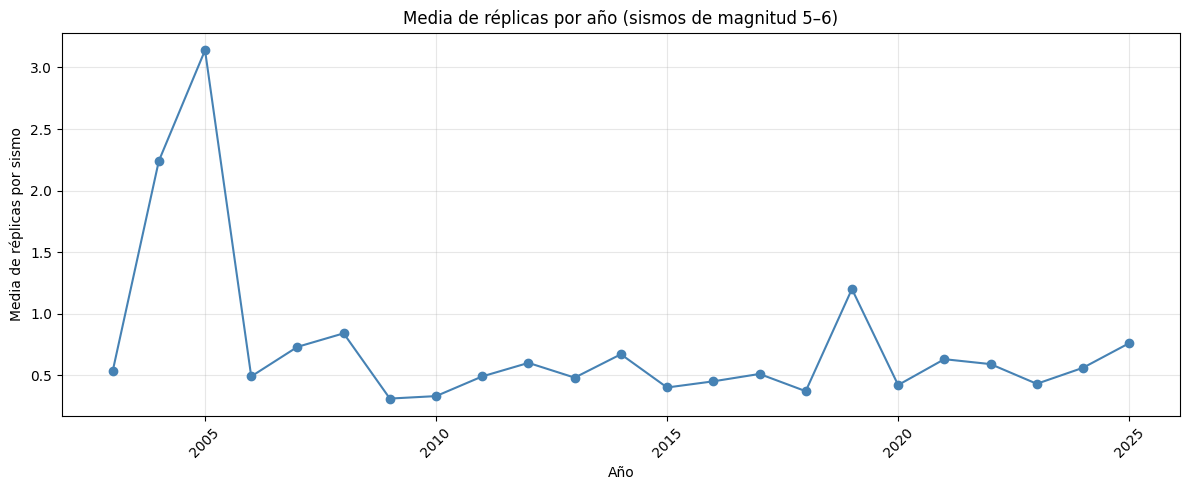

In [ ]:
import matplotlib.pyplot as plt

medianos = df[df["mainshock_mag"].between(5, 6)]

replicas_anuales = (
    medianos.groupby(medianos["mainshock_time"].dt.year)["n_aftershocks"]
    .mean()
    .round(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    replicas_anuales.index,
    replicas_anuales.values,
    marker="o",
    linestyle="-",
    color="steelblue"
)

plt.title("Media de réplicas por año (sismos de magnitud 5–6)")
plt.xlabel("Año")
plt.ylabel("Media de réplicas por sismo")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se puede observar que la media de réplicas fluctúa entre años, pero los valores de 2024 y 2025 no evidencian una caída respecto de los años inmediatamente anteriores.

In [ ]:
pd.DataFrame({"entrenamiento (%)": pd.Series(a_intervalo(y_train)).value_counts(normalize=True).reindex(CLASES) * 100,
              "test (%)": pd.Series(a_intervalo(y_test)).value_counts(normalize=True).reindex(CLASES) * 100}).round(1)

,entrenamiento (%),test (%)
ninguna (0),87.800,89.100
pocas (1–2),9.300,8.100
moderadas (3–10),2.200,2.200
muchas (11+),0.700,0.700


En este caso no estratificamos, pero se observan que las proporciones de cada intervalo quedan parecidas

**Validación cruzada temporal**: utilizamos TimeSeriesSplit para entrenar el modelo con un tramo de datos y validarlo con el siguiente, respetando siempre el orden cronológico. Así, el modelo se evalúa con datos posteriores a los utilizados en cada entrenamiento, siguiendo el mismo criterio que aplicamos en la división entre entrenamiento y test.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

cv = TimeSeriesSplit(n_splits=5)

pd.DataFrame([{"entrena hasta": df["mainshock_time"].iloc[e[-1]].date(),
               "valida desde": df["mainshock_time"].iloc[v[0]].date(),
               "valida hasta": df["mainshock_time"].iloc[v[-1]].date(),
               "filas entrenamiento": len(e), "filas validación": len(v)}
              for e, v in cv.split(X_train)],
             index=[f"fold {i + 1}" for i in range(5)])

,entrena hasta,valida desde,valida hasta,filas entrenamiento,filas validación
fold 1,2006-11-18,2006-11-18,2010-04-14,2843,2838
fold 2,2010-04-14,2010-04-14,2012-10-13,5681,2838
fold 3,2012-10-13,2012-10-14,2015-06-11,8519,2838
fold 4,2015-06-11,2015-06-11,2018-06-01,11357,2838
fold 5,2018-06-01,2018-06-01,2021-05-23,14195,2838


## La métrica: f1 macro

Las clases están muy desbalanceadas: aproximadamente el 88 % de los sismos pertenece a la categoría «ninguna». En este contexto, la accuracy puede resultar engañosa, ya que un modelo que siempre predice «ninguna» podría alcanzar un 88 % de aciertos sin identificar correctamente las demás categorías.

Por este motivo, utilizamos el F1 macro como métrica principal de selección, ya que calcula el F1 de cada una de las cuatro clases y los promedia dando a todas el mismo peso, independientemente de su frecuencia. Así, el rendimiento en las categorías menos representadas también influye en la elección del modelo.

In [ ]:
from sklearn.metrics import f1_score, recall_score, make_scorer

# todos los modelos reciben el conteo; la nota se pone sobre el intervalo
def f1_macro(y_conteo, y_pred):
    return f1_score(a_intervalo(y_conteo), y_pred, average="macro", labels=CLASES)

def recall_de(clase):
    return lambda y_conteo, y_pred: recall_score(a_intervalo(y_conteo), y_pred, labels=[clase], average="macro", zero_division=0)

F1 = make_scorer(f1_macro)
# el recall de cada intervalo lo usamos recién al final, en el trade-off
RECALLS = {"f1 macro": F1, **{f"recall {c}": make_scorer(recall_de(c)) for c in CLASES}}

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

class Clasificador(BaseEstimator, ClassifierMixin):
    '''Un clasificador común: recibe el conteo, lo pasa a intervalo y aprende el intervalo.'''
    def __init__(self, modelo=None):
        self.modelo = modelo
    def fit(self, X, y):
        self.modelo_ = clone(self.modelo).fit(X, a_intervalo(y))
        self.classes_ = self.modelo_.classes_
        return self
    def predict(self, X):
        return self.modelo_.predict(X)

def crudas(modelo):
    '''Magnitud y profundidad tal como vienen, escaladas, y el modelo.'''
    return Pipeline([("columnas", ColumnTransformer([("escalar", StandardScaler(),
                                                     ["mainshock_mag", "mainshock_depth"])])),
                     ("modelo", modelo)])

resultados = {}
def validar(nombre, pipeline):
    r = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=F1, n_jobs=-1)
    resultados[nombre] = {"f1 macro": r["test_score"].mean(), "desvío": r["test_score"].std()}
    return pd.DataFrame(resultados).T.round(3)

## El piso
Un modelo que contesta siempre "ninguna", sin mirar ninguna columna.

In [ ]:
from sklearn.dummy import DummyClassifier

piso = crudas(Clasificador(DummyClassifier(strategy="most_frequent")))    # dice siempre "ninguna"
validar("piso (siempre ninguna)", piso)

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001


# Modelos


## Regresión Logística


In [ ]:
from sklearn.linear_model import LogisticRegression

logistica = crudas(Clasificador(LogisticRegression(max_iter=3000, random_state=SEMILLA)))
validar("regresión logística", logistica)

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001
regresión logística,0.378,0.037


In [ ]:
logistica_bal = crudas(Clasificador(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEMILLA)))
validar("regresión logística (balanced)", logistica_bal)

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001
regresión logística,0.378,0.037
regresión logística (balanced),0.326,0.022


Los resultados obtenidos muestran que la regresión logística sin balanceo alcanza un F1 macro de 0.378, mientras que la versión balanceada obtiene 0.326. Esta diferencia permite observar que el balanceo no necesariamente mejora el desempeño del modelo, por lo que resulta importante comparar ambas alternativas en lugar de asumir que una compensación del desbalance producirá mejores resultados.

## Regresión de Poisson con las columnas crudas
Probamos una regresión de Poisson, diseñada específicamente para modelar variables de conteo, como el número de réplicas de un sismo. A diferencia de la regresión logística, que trata a los intervalos como categorías aisladas, Poisson modela directamente el proceso generativo continuo: a través de su función de enlace logarítmica, garantiza valores esperados positivos y refleja fielmente que un incremento lineal en la magnitud del sismo multiplica la cantidad esperada de réplicas.

En esta primera prueba utilizamos las columnas crudas, sin aplicar transformaciones adicionales, para evaluar qué tan bien funciona el modelo con las variables originales. La idea es obtener una estimación de la cantidad esperada de réplicas para cada sismo y utilizarla para determinar el intervalo de cantidad de réplicas más probable.

Por ahora, mantenemos el hiperparámetro empuje en 0, de modo que no se aplique ningún ajuste adicional a la estimación. Más adelante evaluaremos cómo modificar este parámetro influye en las predicciones y en el desempeño del clasificador.

In [ ]:
from sklearn.linear_model import PoissonRegressor
from scipy.stats import poisson

class PoissonIntervalos(BaseEstimator, ClassifierMixin):
    '''Regresión de Poisson sobre el conteo; contesta el intervalo más probable.

    alpha:  regularización de la regresión de Poisson.
    empuje: 0 = elige el intervalo más probable; más alto = se anima más a decir
            que hay réplicas (divide cada probabilidad por lo común que es ese intervalo).
    '''
    def __init__(self, alpha=1.0, empuje=0.0):
        self.alpha = alpha
        self.empuje = empuje

    def fit(self, X, y):
        self.regresion_ = PoissonRegressor(alpha=self.alpha, max_iter=1000).fit(X, y)
        self.classes_ = np.array(CLASES)
        intervalos = a_intervalo(y)
        self.frecuencia_ = np.array([(intervalos == c).mean() for c in CLASES])
        return self

    def replicas_esperadas(self, X):
        return self.regresion_.predict(X)

    def predict_proba(self, X):
        mu = self.replicas_esperadas(X)
        acumulada = [poisson.cdf(k, mu) for k in CORTES]
        return np.column_stack([acumulada[0]] +
                               [acumulada[i] - acumulada[i - 1] for i in range(1, len(CORTES))] +
                               [1 - acumulada[-1]])

    def predict(self, X):
        P = self.predict_proba(X) / np.maximum(self.frecuencia_, 1e-6) ** self.empuje
        return self.classes_[P.argmax(axis=1)]

Antes de evaluarla, veamos qué contesta para tres sismos inventados:

In [ ]:
# qué contesta para tres sismos inventados, a 30 km de profundidad
ejemplo = crudas(PoissonIntervalos()).fit(X_train, y_train)
sismos = pd.DataFrame({"mainshock_mag": [4.5, 6.0, 7.5], "mainshock_depth": 30.0, "region_mc": 4.5})
pd.DataFrame(ejemplo.predict_proba(sismos), columns=CLASES, index=["M4,5", "M6,0", "M7,5"]).mul(100).round(1).assign(
    **{"réplicas esperadas": ejemplo.named_steps["modelo"].replicas_esperadas(
        ejemplo.named_steps["columnas"].transform(sismos)).round(1),
       "respuesta": ejemplo.predict(sismos)})

,ninguna (0),pocas (1–2),moderadas (3–10),muchas (11+),réplicas esperadas,respuesta
"M4,5",79.300,20.500,0.200,0.000,0.200,ninguna (0)
"M6,0",2.300,24.800,72.800,0.200,3.800,moderadas (3–10)
"M7,5",0.000,0.000,0.000,100.000,62.000,muchas (11+)


In [ ]:
poisson_crudo = crudas(PoissonIntervalos())
validar("Poisson (mag + prof)", poisson_crudo)

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001
regresión logística,0.378,0.037
regresión logística (balanced),0.326,0.022
Poisson (mag + prof),0.442,0.020


Los resultados muestran que el modelo de Poisson, utilizando las variables de magnitud y profundidad del sismo, obtiene un F1 macro de 0.442 , superior al de las dos variantes de regresión logística y al clasificador de referencia.

En comparación con la regresión logística convencional, Poisson mejora el F1 macro de 0.378 a 0.442, una diferencia de 0.064 puntos. Además, presenta un desvío de 0.020, menor que el de la regresión logística sin balanceo (0.037), lo que indica una menor variabilidad entre las evaluaciones realizadas.

Antes de seguir, buscamos si el error tiene algún patrón. Comparamos, **por región**, las réplicas reales con las que esperaba el modelo, usando sólo predicciones de validación (sismos que el modelo no había visto al entrenar).

Luego, agrupa los resultados por región y calcula la razón real / predicho:

* Cercana a 1: el modelo estima bien la cantidad total de réplicas.

* Mayor que 1: subestima las réplicas.

* Menor que 1: sobreestima las réplicas.

In [ ]:
def esperadas_de_validacion(pipeline):
    '''Réplicas esperadas para cada sismo, calculadas cuando ese sismo estaba en validación.'''
    esperadas = pd.Series(np.nan, index=X_train.index)
    for entrena, valida in cv.split(X_train):
        pipeline.fit(X_train.iloc[entrena], y_train.iloc[entrena])
        columnas = pipeline[:-1].transform(X_train.iloc[valida])          # todo menos el modelo
        esperadas.iloc[valida] = pipeline[-1].replicas_esperadas(columnas)
    return esperadas.dropna()

def real_sobre_predicho(esperadas):
    t = pd.DataFrame({"real": y_train.loc[esperadas.index], "esperadas": esperadas,
                      "region": X_train.loc[esperadas.index, "region"],
                      "Mc": X_train.loc[esperadas.index, "region_mc"],
                      "mag": X_train.loc[esperadas.index, "mainshock_mag"]})
    t = t[t["mag"] < 6.5]          # sin los megasismos, que en una suma tapan todo lo demás
    r = t.groupby("region").agg(Mc=("Mc", "first"), real=("real", "sum"), esperadas=("esperadas", "sum"))
    r["real / esperadas"] = r["real"] / r["esperadas"]
    return r.sort_values("Mc")

esperadas_crudo = esperadas_de_validacion(poisson_crudo)
real_sobre_predicho(esperadas_crudo).round(2)

,Mc,real,esperadas,real / esperadas
region,,,,
mexico_ca,4.200,2160,"1,582.940",1.360
andes,4.500,416,"1,714.830",0.240
japan,4.600,593,"1,792.920",0.330
sumatra_java,4.600,637,"1,535.810",0.410
philippines,4.700,510,"1,022.360",0.500


La mayoría de regiones queda por debajo de 1, pero México queda por encima con una razón de 1,36, lo que indica que el modelo subestima la cantidad de réplicas; en Filipinas, es 0,50, por lo que las sobreestima. Esto sugiere que el modelo no representa de la misma manera la actividad sísmica de ambas regiones, incluso para sismos de magnitud similar.

El problema es que la magnitud mínima de detección (Mc) varía entre regiones. En México es 4,2 y en Filipinas, 4,7, por lo que una réplica tiene más posibilidades de registrarse en México que en Filipinas. Por ejemplo, para un sismo principal de magnitud 5, la diferencia respecto al Mc es de 0,8 en México y de 0,3 en Filipinas.

Si el modelo utiliza únicamente la magnitud del sismo principal, no contempla esta diferencia en las condiciones de detección. Por eso, incorporamos la variable mag_sobre_mc, que representa cuánto supera la magnitud del sismo principal al Mc de su región:

`mag_sobre_mc = mainshock_mag - region_mc`

Así, el modelo dispone de información adicional sobre las condiciones de detección de cada región.

# Nueva Columna


## Poisson con mag_sobre_mc

Para tener en cuenta esta diferencia, incorporamos mag_sobre_mc, que mide cuánto supera la magnitud del sismo principal a la magnitud mínima de detección de su región. Esta variable se calcula dentro del pipeline para mantener el procesamiento integrado al entrenamiento y la validación del modelo.

Así, Poisson utiliza una medida más informativa que la magnitud por sí sola, al considerar también las condiciones de detección de cada región.

In [ ]:
class MagSobreMc(BaseEstimator, TransformerMixin):
    '''Reemplaza la magnitud por cuánto supera al Mc de su región; la profundidad pasa igual.'''
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return pd.DataFrame({"mag_sobre_mc": X["mainshock_mag"] - X["region_mc"],
                             "profundidad":  X["mainshock_depth"]}, index=X.index)

def con_mc(modelo):
    return Pipeline([("columnas", MagSobreMc()),
                     ("escalar", StandardScaler()),
                     ("modelo", modelo)])

poisson_mc = con_mc(PoissonIntervalos())
validar("Poisson (mag_sobre_mc + prof)", poisson_mc)

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001
regresión logística,0.378,0.037
regresión logística (balanced),0.326,0.022
Poisson (mag + prof),0.442,0.020
Poisson (mag_sobre_mc + prof),0.444,0.021


Al incorporar `mag_sobre_mc`, el f1 mejora apenas de 0.442 a 0,444. Pero esto, arregló lo que queríamos mejorar? Repetimos la tabla por región.

In [ ]:
esperadas_mc = esperadas_de_validacion(con_mc(PoissonIntervalos()))
pd.DataFrame({"Mc": real_sobre_predicho(esperadas_crudo)["Mc"],
              "real / esperadas, magnitud cruda": real_sobre_predicho(esperadas_crudo)["real / esperadas"],
              "real / esperadas, mag_sobre_mc": real_sobre_predicho(esperadas_mc)["real / esperadas"]}).round(2)

,Mc,"real / esperadas, magnitud cruda","real / esperadas, mag_sobre_mc"
region,,,
mexico_ca,4.200,1.360,0.830
andes,4.500,0.240,0.260
japan,4.600,0.330,0.430
sumatra_java,4.600,0.410,0.530
philippines,4.700,0.500,0.770


Podemos ver que la corrección mejora el comportamiento del modelo a nivel regional: México y Filipinas, que antes presentaban una diferencia considerable en sus valores (1,36 frente a 0,50), ahora quedan mucho más cerca (0,83 y 0,77, respectivamente). Esto indica que se corrigió una discrepancia que existía entre ambas regiones.

La mejora se refleja poco en el F1 macro porque estas regiones representan solo una parte del conjunto de datos y la métrica está influida por el desempeño en las distintas clases de réplicas, especialmente las más frecuentes. Por lo tanto, una mejora regional puede ser relevante sin producir un cambio importante en la métrica global.

## Nuevas columnas: Region y sismos en los 30 dias previos


El análisis por región dejó una pista: los Andes siguen presentando un valor muy por debajo de 1 (0,26), y la magnitud de completitud (Mc) no parece explicar esa diferencia.

Para evaluar su aporte, probamos distintas configuraciones de a una por vez, manteniendo el mismo modelo de Poisson y el resto de las condiciones constantes. Así podemos identificar qué variables mejoran las predicciones y cuáles no aportan información adicional.



* `Región`: incorporamos la región geográfica para comprobar si existen diferencias sistemáticas en la productividad de réplicas que el modelo no logra capturar únicamente con la magnitud y la profundidad.

* `Sismos en los 30 días previos`: probamos si la actividad sísmica reciente de una zona aporta información adicional. Esta variable podría indicar que una región ya estaba activa antes del sismo analizado.


In [ ]:
class ColumnasCandidatas(BaseEstimator, TransformerMixin):
    '''mag_sobre_mc + profundidad (siempre), con interruptores para probar columnas nuevas.'''
    def __init__(self, con_region=False, con_previos=False):
        self.con_region = con_region
        self.con_previos = con_previos
    def fit(self, X, y=None):
        self.regiones_ = sorted(X["region"].unique())          # se aprende sólo del train
        return self
    def transform(self, X):
        salida = pd.DataFrame({"mag_sobre_mc": X["mainshock_mag"] - X["region_mc"],
                               "profundidad":  X["mainshock_depth"]}, index=X.index)
        if self.con_region:
            for r in self.regiones_[1:]:                          # una columna 0/1 por región
                salida[f"region_{r}"] = (X["region"] == r).astype(float)
        if self.con_previos:
            salida["log_previos_30d"] = np.log1p(X["n_prior_30d"])  # sismos en los 30 días anteriores
        return salida

def probar(**interruptores):
    p = Pipeline([("columnas", ColumnasCandidatas(**interruptores)), ("escalar", StandardScaler()),
                  ("modelo", PoissonIntervalos())])
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=F1, n_jobs=-1)
    return {"f1 macro": r["test_score"].mean(), "desvío": r["test_score"].std(),
            **{f"fold {i + 1}": v for i, v in enumerate(r["test_score"])}}

columnas_probadas = pd.DataFrame({
    "mag_sobre_mc ": probar(),
    "+ región (una columna por región)":           probar(con_region=True),
    "+ sismos en los 30 días previos":             probar(con_previos=True),
}).T
columnas_probadas.round(3)

,f1 macro,desvío,fold 1,fold 2,fold 3,fold 4,fold 5
mag_sobre_mc,0.444,0.021,0.443,0.465,0.461,0.445,0.406
+ región (una columna por región),0.444,0.015,0.428,0.462,0.461,0.444,0.428
+ sismos en los 30 días previos,0.460,0.033,0.449,0.461,0.516,0.459,0.413


La incorporación de la región no mejora el F1 macro (0,444 frente a 0,444), por lo que no se observa un aporte al desempeño general del modelo. Por otro lado, los sismos ocurridos en los 30 días previos muestran una mejora, pero esta no supera el desvío y, por lo tanto, no podemos asegurar que sea significativa y consistente. Así que descartamos estas dos columnas.



# Comparación de familias de modelos

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.stats import nbinom

# 1. Modelo simple sobre las mismas columnas nuevas (mag_sobre_mc + profundidad)
validar("regresión logística (mag_sobre_mc)", con_mc(Clasificador(
    LogisticRegression(max_iter=3000, random_state=SEMILLA))))
validar("regresión logística balanced (mag_sobre_mc)", con_mc(Clasificador(
    LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEMILLA))))

# 2. Familia Bosques (Random Forest)
bosque = con_mc(Clasificador(RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20, random_state=SEMILLA, n_jobs=-1)))
validar("random forest", bosque)

bosque_bal = con_mc(Clasificador(RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20, class_weight="balanced", random_state=SEMILLA, n_jobs=-1)))
validar("random forest (balanced)", bosque_bal)

# 3. Familia Boosting (HistGradientBoosting)
boosting = con_mc(Clasificador(HistGradientBoostingClassifier(
    min_samples_leaf=20, class_weight="balanced", random_state=SEMILLA)))
validar("gradient boosting (balanced)", boosting)

# 4. Binomial Negativa
class BinomialNegativaIntervalos(PoissonIntervalos):
    def fit(self, X, y):
        super().fit(X, y)
        mu = np.maximum(self.replicas_esperadas(X), 1e-6)
        disp = np.mean(((y - mu) ** 2 - mu) / (mu ** 2))
        self.disp_ = max(disp, 1e-4)
        return self

    def predict_proba(self, X):
        mu = np.maximum(self.replicas_esperadas(X), 1e-6)
        n = 1.0 / self.disp_
        p = n / (n + mu)
        acumulada = [nbinom.cdf(k, n, p) for k in CORTES]
        return np.column_stack([acumulada[0]] +
                               [acumulada[i] - acumulada[i - 1] for i in range(1, len(CORTES))] +
                               [1 - acumulada[-1]])

validar("Binomial Negativa (mag_sobre_mc + prof)", con_mc(BinomialNegativaIntervalos()))

,f1 macro,desvío
piso (siempre ninguna),0.235,0.001
regresión logística,0.378,0.037
regresión logística (balanced),0.326,0.022
Poisson (mag + prof),0.442,0.020
Poisson (mag_sobre_mc + prof),0.444,0.021
regresión logística (mag_sobre_mc),0.399,0.028
regresión logística balanced (mag_sobre_mc),0.355,0.025
random forest,0.371,0.055
random forest (balanced),0.325,0.029
gradient boosting (balanced),0.320,0.015


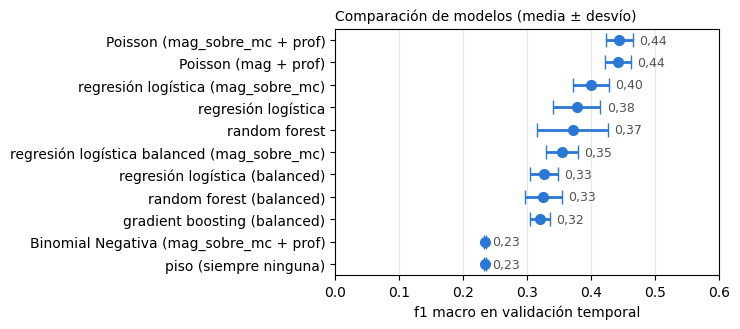

In [ ]:
tabla = pd.DataFrame(resultados).T.sort_values("f1 macro")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.errorbar(tabla["f1 macro"], tabla.index, xerr=tabla["desvío"], fmt="o", color="#2a78d6",
            ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7)
for nombre, fila in tabla.iterrows():
    ax.text(fila["f1 macro"] + fila["desvío"] + 0.01, nombre, f"{fila['f1 macro']:.2f}".replace(".", ","),
            va="center", ha="left", fontsize=9, color="#55534e")
ax.set_xlim(0, 0.6)
ax.set_xlabel("f1 macro en validación temporal")
ax.grid(axis="x", alpha=0.3)
ax.set_title("Comparación de modelos (media ± desvío)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

Observamos que  Poisson con mag_sobre_mc y profundidad obtiene el mejor desempeño entre los modelos evaluados y además, es una de las configuraciones más simples, ya que utiliza solo dos coeficientes. Esto permite lograr buenos resultados sin agregar complejidad innecesaria.

# Ajustes de hiperparámetro
## alpha
El parámetro alpha controla la intensidad de la regularización, es decir, cuánto se limitan los coeficientes del modelo para evitar que dependan demasiado de los datos de entrenamiento. Por defecto vale 1.

En esta etapa probamos distintos valores de alpha para evaluar si una regularización más fuerte o más débil mejora el F1 macro y mantiene un desempeño estable entre los folds.

In [ ]:
from sklearn.model_selection import GridSearchCV

busqueda = GridSearchCV(poisson_mc, {"modelo__alpha": [0.001, 0.01, 0.1, 1, 10]},
                        cv=cv, scoring=F1, n_jobs=-1).fit(X_train, y_train)

tabla_ajuste = pd.DataFrame({"alpha": busqueda.cv_results_["param_modelo__alpha"],
                             "f1 macro": busqueda.cv_results_["mean_test_score"],
                             "desvío": busqueda.cv_results_["std_test_score"]})
tabla_ajuste.round(3)

,alpha,f1 macro,desvío
0,0.001,0.456,0.018
1,0.010,0.453,0.015
2,0.100,0.449,0.018
3,1.000,0.444,0.021
4,10.000,0.354,0.033


In [ ]:
mejor_alpha = busqueda.best_params_["modelo__alpha"]
mejor_alpha

0.001

Entre alpha = 0,001 y alpha = 1 el F1 macro cambia muy poco (de 0,444 a 0,456), y la diferencia queda dentro del desvío observado. Esto sugiere que, al tener solo dos coeficientes, el modelo no presenta una necesidad importante de regularización. En cambio, con alpha = 10, el F1 baja a 0,354 porque los coeficientes quedan demasiado restringidos y el modelo pierde capacidad para distinguir entre sismos.

Nos quedamos con alpha = 0.001


## empuje
Al tratarse de una predicción de sismos y sus posibles réplicas, preferimos avisar de más antes que no detectar un caso en el que sí habrá réplicas. Una falsa alarma puede generar una advertencia innecesaria, pero no detectar un caso real implica perder información potencialmente importante para la prevención y la preparación.

Por eso, estamos dispuestos a aceptar una disminución en el recall de la clase "ninguna" a cambio de detectar más casos de "pocas" y "muchas" réplicas, siempre que el F1 macro se mantenga dentro de un desvío del mejor resultado. Así, el parámetro empuje nos permite priorizar la detección sin deteriorar demasiado el desempeño general del modelo.

In [ ]:
filas = {}
for empuje in [0, 0.2, 0.3, 0.4, 0.5]:
    r = cross_validate(con_mc(PoissonIntervalos(alpha=mejor_alpha, empuje=empuje)), X_train, y_train,
                       cv=cv, scoring=RECALLS, n_jobs=-1)
    filas[empuje] = {"f1 macro": r["test_f1 macro"].mean(), "desvío": r["test_f1 macro"].std(),
                     **{f"recall {c}": r[f"test_recall {c}"].mean() for c in CLASES}}
trade_off = pd.DataFrame(filas).T.rename_axis("empuje")
trade_off.round(3)

,f1 macro,desvío,recall ninguna (0),recall pocas (1–2),recall moderadas (3–10),recall muchas (11+)
empuje,,,,,,
0.000,0.456,0.018,0.929,0.213,0.263,0.429
0.200,0.456,0.021,0.872,0.306,0.286,0.451
0.300,0.449,0.028,0.826,0.371,0.292,0.461
0.400,0.440,0.024,0.758,0.442,0.309,0.478
0.500,0.421,0.028,0.666,0.525,0.317,0.478


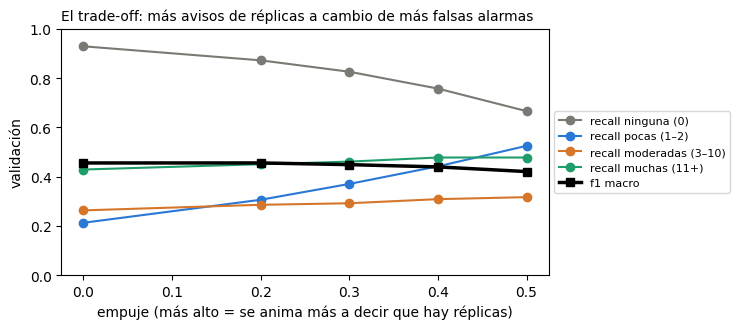

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
colores = ["#7a7974", "#2a78d6", "#d6762a", "#1f9e6b"]
for c, color in zip(CLASES, colores):
    ax.plot(trade_off.index, trade_off[f"recall {c}"], marker="o", color=color, label=f"recall {c}")
ax.plot(trade_off.index, trade_off["f1 macro"], marker="s", color="black", lw=2.5, label="f1 macro")
ax.set_xlabel("empuje (más alto = se anima más a decir que hay réplicas)")
ax.set_ylabel("validación")
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("El trade-off: más avisos de réplicas a cambio de más falsas alarmas", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

Al aumentar el empuje, mejora el recall de las clases “pocas” (de 0,21 a 0,53) y “muchas” (de 0,43 a 0,48), por lo que el modelo detecta más casos con réplicas. Como contrapartida, el recall de “ninguna” baja de 0,93 a 0,67, generando más falsas alarmas.

El F1 macro se mantiene relativamente estable hasta empuje = 0,4 y luego disminuye.

In [ ]:
# regla: el empuje más alto cuyo f1 macro esté dentro de un desvío del mejor
mejor = trade_off["f1 macro"].max()
desvio_mejor = trade_off.loc[trade_off["f1 macro"].idxmax(), "desvío"]
candidatos = trade_off[trade_off["f1 macro"] >= mejor - desvio_mejor]
EMPUJE = candidatos.index.max()

pd.Series({"alpha elegido": mejor_alpha, "mejor f1 macro": round(mejor, 3), "desvío": round(desvio_mejor, 3),
           "empuje elegido": EMPUJE, "f1 macro con ese empuje": round(trade_off.loc[EMPUJE, "f1 macro"], 3)})

,0
alpha elegido,0.001
mejor f1 macro,0.456
desvío,0.021
empuje elegido,0.400
f1 macro con ese empuje,0.440


## ¿La conclusión depende de dónde cortamos los intervalos?


In [ ]:
# ¿la conclusión depende de dónde cortamos? probamos otros esquemas con los mismos modelos
ESQUEMAS = {"0 | 1–5 | 6+":              [0, 5],
            "0 | 1–10 | 11+":            [0, 10],
            "0 | 1–2 | 3–10 | 11+ (el elegido)": [0, 2, 10],
            "0 | 1 | 2–5 | 6+":          [0, 1, 5],
            "0 | 1 | 2–5 | 6–20 | 21+":  [0, 1, 5, 20]}

def f1_con_cortes(cortes, pipeline_de):
    clases = [str(i) for i in range(len(cortes) + 1)]
    intervalo = lambda n: np.array(clases)[np.searchsorted(cortes, np.asarray(n), side="left")]
    notas = []
    for e, v in cv.split(X_train):
        pred = pipeline_de(cortes, clases, intervalo).fit(X_train.iloc[e], y_train.iloc[e]).predict(X_train.iloc[v])
        notas.append(f1_score(intervalo(y_train.iloc[v]), pred, average="macro", labels=clases))
    return np.mean(notas)

class PoissonCortes(PoissonIntervalos):
    '''La misma PoissonIntervalos, pero con otros cortes.'''
    def __init__(self, alpha=1.0, empuje=0.0, cortes=(0, 2, 10), clases=None):
        super().__init__(alpha, empuje); self.cortes = cortes; self.clases = clases
    def fit(self, X, y):
        self.regresion_ = PoissonRegressor(alpha=self.alpha, max_iter=1000).fit(X, y)
        self.classes_ = np.array(self.clases)
        inter = np.array(self.clases)[np.searchsorted(self.cortes, np.asarray(y), side="left")]
        self.frecuencia_ = np.array([(inter == c).mean() for c in self.clases])
        return self
    def predict_proba(self, X):
        mu = self.replicas_esperadas(X)
        acum = [poisson.cdf(k, mu) for k in self.cortes]
        return np.column_stack([acum[0]] + [acum[i] - acum[i - 1] for i in range(1, len(self.cortes))] + [1 - acum[-1]])

class ClasificadorCortes(BaseEstimator, ClassifierMixin):
    def __init__(self, modelo=None, intervalo=None):
        self.modelo = modelo; self.intervalo = intervalo
    def fit(self, X, y):
        self.modelo_ = clone(self.modelo).fit(X, self.intervalo(y)); return self
    def predict(self, X):
        return self.modelo_.predict(X)

filas = {}
for nombre, cortes in ESQUEMAS.items():
    filas[nombre] = {
        "intervalos": len(cortes) + 1,
        "piso": f1_con_cortes(cortes, lambda c, cl, it: con_mc(ClasificadorCortes(DummyClassifier(strategy="most_frequent"), it))),
        "logística (balanced)": f1_con_cortes(cortes, lambda c, cl, it: con_mc(ClasificadorCortes(LogisticRegression(max_iter=3000, class_weight="balanced"), it))),
        "Poisson": f1_con_cortes(cortes, lambda c, cl, it: con_mc(PoissonCortes(alpha=mejor_alpha, empuje=EMPUJE, cortes=c, clases=cl))),
    }
pd.DataFrame(filas).T.round(3)

,intervalos,piso,logística (balanced),Poisson
0 | 1–5 | 6+,3.000,0.313,0.438,0.533
0 | 1–10 | 11+,3.000,0.313,0.432,0.542
0 | 1–2 | 3–10 | 11+ (el elegido),4.000,0.235,0.355,0.440
0 | 1 | 2–5 | 6+,4.000,0.235,0.344,0.439
0 | 1 | 2–5 | 6–20 | 21+,5.000,0.188,0.279,0.404


Al aumentar la cantidad de intervalos, el F1 macro disminuye, incluso para el clasificador de referencia (piso), porque distinguir entre más categorías hace que la clasificación sea más difícil.

Sin embargo, la Poisson mantiene un rendimiento superior al de la regresión logística y al piso en todos los esquemas evaluados. Esto indica que su mejor desempeño no depende únicamente de cómo se definan los intervalos de réplicas, sino que se mantiene al cambiar los puntos de corte.

Por lo tanto, los resultados respaldan la elección de Poisson como una mejor alternativa de modelo, independientemente del esquema de intervalos utilizado.

# El modelo final, leído
## 1. Desempeño en el test
Entrenamos el modelo elegido (`PoissonIntervalos` con `mag_sobre_mc`, `alpha=0.001` y `empuje=0.4`) sobre todo el conjunto de entrenamiento y lo evaluamos una única vez en el conjunto de test (2021–2025)

In [ ]:
from sklearn.metrics import accuracy_score

final = con_mc(PoissonIntervalos(alpha=mejor_alpha, empuje=EMPUJE)).fit(X_train, y_train)
piso.fit(X_train, y_train)

real_test = a_intervalo(y_test)
pred_test = final.predict(X_test)
pred_piso = piso.predict(X_test)

pd.DataFrame({
    "f1 macro validación": [resultados["piso (siempre ninguna)"]["f1 macro"], trade_off.loc[EMPUJE, "f1 macro"]],
    "desvío validación":   [resultados["piso (siempre ninguna)"]["desvío"],   trade_off.loc[EMPUJE, "desvío"]],
    "f1 macro test":       [f1_score(real_test, pred_piso, average="macro", labels=CLASES),
                            f1_score(real_test, pred_test, average="macro", labels=CLASES)],
    "accuracy test":       [accuracy_score(real_test, pred_piso), accuracy_score(real_test, pred_test)]},
    index=["piso (siempre ninguna)", f"Poisson final (alpha={mejor_alpha}, empuje={EMPUJE})"]).round(3)

,f1 macro validación,desvío validación,f1 macro test,accuracy test
piso (siempre ninguna),0.235,0.001,0.236,0.891
"Poisson final (alpha=0.001, empuje=0.4)",0.440,0.024,0.500,0.751


El modelo de Poisson alcanza un F1 macro de 0,50 en test, frente a 0,24 del piso: más del doble, lo que muestra una mejora importante en la identificación de las distintas clases.

La accuracy baja de 0,89 a 0,75, algo esperable por el desbalance de los datos: como cerca del 90 % de los sismos pertenece a la clase "ninguna", el piso consigue una accuracy alta prediciendo siempre esa categoría, pero no detecta las demás.

Aceptamos una menor accuracy porque, mediante el empuje, priorizamos detectar más sismos con posibles réplicas, aunque eso genere más falsas alarmas. Por eso el F1 macro es más informativo que la accuracy para nuestro objetivo.

El F1 macro en test (0,50) es mayor que en validación (0,44 ± 0,024). Lo atribuimos a dos cosas: la clase "muchas" tiene sólo 29 casos en test, así que dos o tres aciertos más mueven bastante su f1, y el modelo final se entrena con todo el entrenamiento, mientras que los folds de validación usan menos datos.

In [ ]:
real_si = real_test != CLASES[0]
pred_si = pred_test != CLASES[0]
pd.Series({"sismos que tuvieron réplicas": int(real_si.sum()),
           "de esos, el modelo avisó que habría (%)": round(pred_si[real_si].mean() * 100, 1),
           "veces que avisó y no hubo (falsas alarmas)": int((pred_si & ~real_si).sum()),
           "veces que avisó y sí hubo": int((pred_si & real_si).sum())})

,0
sismos que tuvieron réplicas,466.000
"de esos, el modelo avisó que habría (%)",59.700
veces que avisó y no hubo (falsas alarmas),792.000
veces que avisó y sí hubo,278.000


De los 466 sismos del test que tuvieron réplicas, el modelo detectó aproximadamente el 60 %. El costo son unas 800 falsas alarmas: por cada aviso correcto hay aproximadamente tres que no corresponden a sismos con réplicas.

Esto responde a la decisión de priorizar el recall. El empuje permite ajustar ese equilibrio: si lo aumentamos detectamos más casos, pero con más falsas alarmas; si lo reducimos, el modelo es más conservador. En la práctica, el modelo sirve para priorizar qué sismos vigilar, no para emitir alertas.

## 2. Dónde se equivoca el modelo
Analizamos el reporte por clase y las matrices de confusión normalizadas por fila (sensibilidad / *recall*: de los sismos que realmente tuvieron X réplicas, qué proporción detectó el modelo) y por columna (precisión: cuando el modelo advierte X réplicas, qué proporción de veces acierta).

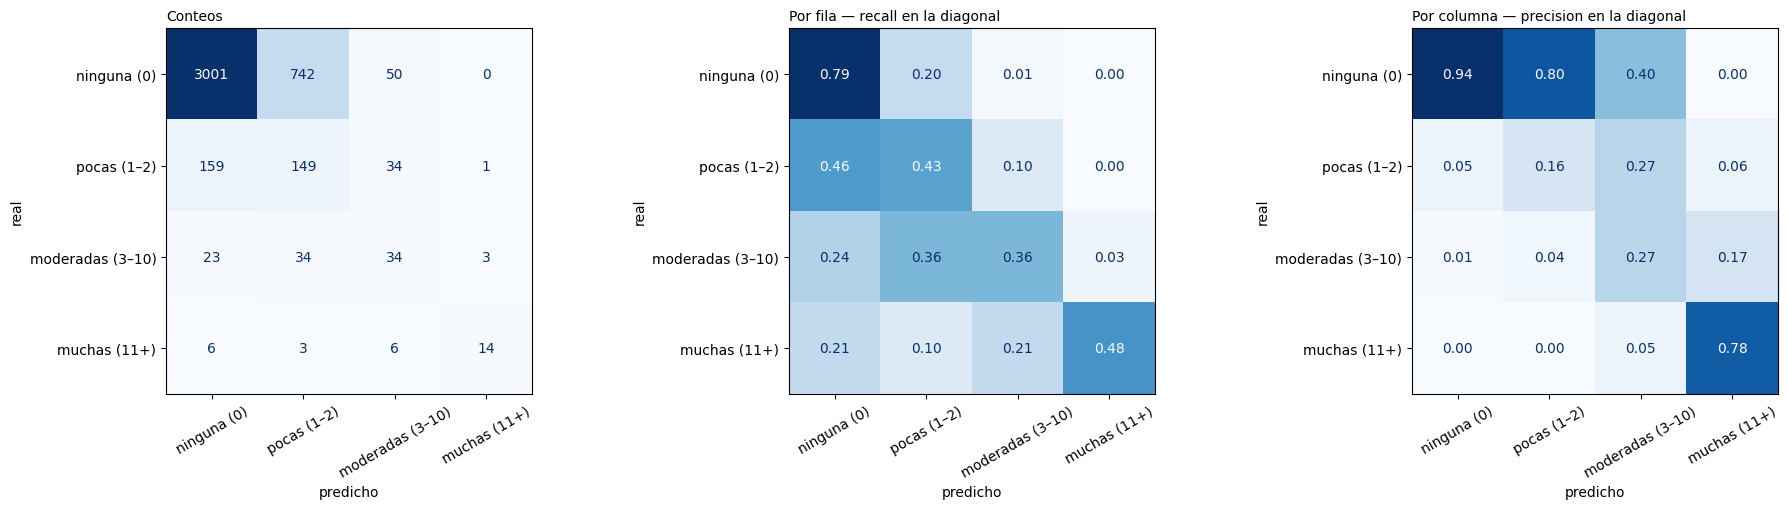

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, norm, titulo, fmt in [(axes[0], None, "Conteos", "d"),
                              (axes[1], "true", "Por fila — recall en la diagonal", ".2f"),
                              (axes[2], "pred", "Por columna — precision en la diagonal", ".2f")]:
    ConfusionMatrixDisplay.from_predictions(real_test, pred_test, labels=CLASES, ax=ax, cmap="Blues",
                                            colorbar=False, normalize=norm, values_format=fmt, xticks_rotation=30)
    ax.set_title(titulo, fontsize=10, loc="left"); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout()
plt.show()

Las matrices muestran que el modelo identifica bien la categoría "ninguna (0)", con un recall del 79 % y una precisión del 94 %. Su capacidad para distinguir "pocas (1–2)", "moderadas (3–10)" y "muchas (11+)" es más limitada, con recalls del 43 %, 36 % y 48 %. Aunque "muchas" tiene una precisión del 78 %, el modelo encuentra menos de la mitad de los casos reales de esa clase. En conjunto, reconoce bien la ausencia de réplicas, pero le cuesta identificar y diferenciar las categorías con réplicas.

In [ ]:
from sklearn.metrics import classification_report

pd.DataFrame(classification_report(real_test, pred_test, labels=CLASES, output_dict=True, zero_division=0)).T.round(3)

,precision,recall,f1-score,support
ninguna (0),0.941,0.791,0.860,"3,793.000"
pocas (1–2),0.161,0.434,0.234,343.000
moderadas (3–10),0.274,0.362,0.312,94.000
muchas (11+),0.778,0.483,0.596,29.000
accuracy,0.751,0.751,0.751,0.751
macro avg,0.538,0.518,0.500,"4,259.000"
weighted avg,0.862,0.751,0.795,"4,259.000"


In [ ]:
tramo_test = pd.cut(X_test["mainshock_mag"], [4, 5, 6, 7, 10], labels=["4–5", "5–6", "6–7", "7 o más"], right=False)
pd.DataFrame({"tramo": tramo_test, "acierta": real_test == pred_test}).groupby("tramo", observed=True).agg(
    sismos=("acierta", "size"),
    acierta_el_intervalo_pct=("acierta", lambda s: round(s.mean() * 100, 1)))

,sismos,acierta_el_intervalo_pct
tramo,,
4–5,3293,85.200
5–6,878,40.400
6–7,77,36.400
7 o más,11,72.700


El modelo acierta más en los extremos: los sismos de M4–5 casi siempre caen en "ninguna" (85 %) y los de M7 o más, en "muchas" (73 %). Los tramos intermedios, M5–6 y M6–7, son los más difíciles (40 % y 36 %), porque la cantidad de réplicas que el modelo espera ahí queda cerca de los cortes de 2 y 10, y un sismo puede caer en uno u otro intervalo por poca diferencia.

In [ ]:
df_test_analisis = df.iloc[corte:].copy()
df_test_analisis["real"] = real_test
df_test_analisis["predicho"] = pred_test
df_test_analisis["mag_sobre_mc"] = df_test_analisis["mainshock_mag"] - df_test_analisis["region_mc"]
columnas_ver = ["mainshock_time", "mainshock_place", "region", "mainshock_mag", "region_mc",
                "mag_sobre_mc", "mainshock_depth", "root_is_mainshock", "n_aftershocks", "predicho"]

print("Sismos sin réplicas donde el modelo predijo actividad moderada o muchas:")
display(df_test_analisis[(df_test_analisis["real"] == "ninguna (0)") &
                         (df_test_analisis["predicho"].isin(["moderadas (3–10)", "muchas (11+)"]))][columnas_ver].head(5))

print("\nSismos con muchas réplicas (11+) subestimados por el modelo:")
display(df_test_analisis[(df_test_analisis["real"] == "muchas (11+)") &
                         (df_test_analisis["predicho"].isin(["ninguna (0)", "pocas (1–2)"]))][columnas_ver].head(5))

Sismos sin réplicas donde el modelo predijo actividad moderada o muchas:


,mainshock_time,mainshock_place,region,mainshock_mag,region_mc,mag_sobre_mc,mainshock_depth,root_is_mainshock,n_aftershocks,predicho
17087,2021-06-10 23:27:02+00:00,"102 km S of Sámara, Costa Rica",mexico_ca,5.700,4.200,1.500,10.000,True,0,moderadas (3–10)
17302,2021-09-05 08:42:13+00:00,"291 km SSE of Cabo San Lucas, Mexico",mexico_ca,5.500,4.200,1.300,10.000,True,0,moderadas (3–10)
17411,2021-10-16 18:27:28+00:00,"73 km SSW of George Town, Cayman Islands",mexico_ca,5.400,4.200,1.200,10.000,True,0,moderadas (3–10)
17493,2021-11-23 05:56:32+00:00,"81 km SW of Acajutla, El Salvador",mexico_ca,5.500,4.200,1.300,18.000,True,0,moderadas (3–10)
17635,2022-01-10 08:36:02+00:00,"23 km NW of Trancas, Argentina",andes,5.600,4.500,1.100,8.000,True,0,moderadas (3–10)



Sismos con muchas réplicas (11+) subestimados por el modelo:


,mainshock_time,mainshock_place,region,mainshock_mag,region_mc,mag_sobre_mc,mainshock_depth,root_is_mainshock,n_aftershocks,predicho
17218,2021-08-03 00:57:10+00:00,"Nicobar Islands, India region",sumatra_java,4.600,4.600,-0.000,10.000,True,12,ninguna (0)
17309,2021-09-08 00:55:22+00:00,"1 km NE of Llano Grande, Mexico",mexico_ca,4.200,4.200,0.000,35.000,True,15,ninguna (0)
18080,2022-07-04 05:35:51+00:00,"204 km SE of Port Blair, India",sumatra_java,4.700,4.600,0.100,10.000,True,28,ninguna (0)
18155,2022-08-04 03:29:56+00:00,"Izu Islands, Japan region",japan,4.900,4.600,0.300,10.000,True,18,pocas (1–2)
18922,2023-05-14 07:03:24+00:00,"157 km SSE of Shimoda, Japan",japan,4.700,4.600,0.100,19.914,True,14,ninguna (0)


**Falsas alarmas:** sismos de M5,4 a M5,7 sin ninguna réplica. El modelo esperaba varias réplicas porque son sismos medianos y someros, con mag_sobre_mc entre 1,1 y 1,5. Pero varios de estos sismos ocurrieron lejos de la costa: a 102 km de Sámara, a 291 km de Cabo San Lucas, a 73 km de las Islas Caimán y a 81 km de Acajutla. Nuestra hipótesis es que el Mc de la región, que es único para toda la región (4,2 en México y Centroamérica), describe bien la detección cerca de la costa, donde están las estaciones, pero no mar adentro. Allí el umbral real de detección sería más alto y las réplicas existirían pero no quedarían registradas en el catálogo. Además, varios tienen profundidad exactamente 10 km, un valor que el catálogo asigna por defecto cuando no puede medirla, así que la profundidad con la que el modelo calcula su predicción tampoco es confiable.

**Subestimaciones:** sismos chicos con más de 10 réplicas. Son el error opuesto. Los sismos principales apenas superan el Mc (mag_sobre_mc entre 0 y 0,3), así que el modelo esperaba ninguna réplica, y sin embargo tuvieron entre 12 y 28. Se concentran en zonas como las islas Nicobar y Andamán, y las islas Izu, en Japón, conocidas por sus enjambres sísmicos: secuencias de muchos sismos de tamaño parecido, sin uno principal claro, que no siguen la ley de Utsu. También es posible que algunos sean precursores de un sismo mayor. Como usamos root, el sismo que abre la secuencia recibe las réplicas de toda la secuencia, incluidas las de un sismo más grande que vino después. Intentamos comprobarlo con root_is_mainshock, pero con mainshock=root esa columna es siempre verdadera por construcción. Para confirmarlo hace falta la magnitud máxima de cada secuencia, cruzando con la versión largest del pipeline.

En los dos casos, el modelo responde con lo que sabe en el momento del sismo, y en ese momento ni la detección mar adentro ni la evolución futura de la secuencia están disponibles. Estos errores son el costo de predecir sin fuga.

## 3. En qué se apoya el modelo
Inspeccionamos los coeficientes aprendidos por la regresión de Poisson (en unidades reales) y medimos la importancia por permutación de las columnas de entrada en el conjunto de test.

In [ ]:
reg = final.named_steps["modelo"].regresion_
coef = reg.coef_ / final.named_steps["escalar"].scale_   # de escala estándar a unidades reales

display(pd.DataFrame({
    "coeficiente (por unidad)": coef,
    "multiplica las réplicas esperadas por": np.exp(coef)},
    index=["mag_sobre_mc (por punto de magnitud)", "profundidad (por km)"]).round(3))

pd.Series({"α de Utsu equivalente": round(coef[0] / np.log(10), 2),
           "efecto de 100 km más de profundidad": round(np.exp(coef[1] * 100), 2)})

,coeficiente (por unidad),multiplica las réplicas esperadas por
mag_sobre_mc (por punto de magnitud),2.025,7.573
profundidad (por km),-0.010,0.990


,0
α de Utsu equivalente,0.880
efecto de 100 km más de profundidad,0.370


* **`mag_sobre_mc` (signo positivo):** cada punto de magnitud por encima del Mc de la región multiplica por unos 7,6 las réplicas esperadas. Eso equivale a una pendiente α ≈ 0,88, dentro del rango de 0,8 a 1 de la ley de productividad de Utsu, así que el modelo aprendió una relación conocida en sismología. No es fuga: la magnitud se conoce minutos después del sismo, y `region_mc` es un umbral fijo de cada región.
* **`profundidad` (signo negativo):** cada km más profundo baja las réplicas esperadas alrededor de un 1 %, o sea que 100 km más profundo las reduce a cerca de un tercio (0,37). Los sismos profundos ocurren con más presión y temperatura, lo que dificulta las fracturas secundarias que generan réplicas.

### Importancia por permutación (sobre el test)
Desordenamos una columna por vez y medimos cuánto baja el f1 macro:

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final, X_test, y_test, scoring=make_scorer(f1_macro), n_repeats=20,
                              random_state=SEMILLA, n_jobs=-1)
pd.DataFrame({"cuánto baja el f1 macro al desordenarla": perm.importances_mean, "desvío": perm.importances_std},
             index=X_test.columns).sort_values("cuánto baja el f1 macro al desordenarla", ascending=False).round(3)

,cuánto baja el f1 macro al desordenarla,desvío
mainshock_mag,0.249,0.006
mainshock_depth,0.066,0.010
region_mc,0.054,0.012
region,0.000,0.000
n_prior_30d,0.000,0.000


Podemos observar que:
* `mainshock_mag`: es la columna más importante, con una caída de 0,249 en el f1 macro.
* `mainshock_depth`: aporta menos, con una caída de 0,066.
* `region_mc`: también aporta, porque forma parte de `mag_sobre_mc`.
* `region` y `n_prior_30d` dan 0 porque el modelo final no las usa.

# Lo que no anduvo
- **Predecir el número exacto de réplicas:** la cantidad varía demasiado entre sismos parecidos, por eso trabajamos con intervalos.
- **Clasificación directa:** la logística y el random forest tuvieron peores resultados que Poisson; en el caso de la logística, también con todos los puntos de corte probados.
- **Binomial negativa:** pensada para la sobredispersión, terminó contestando siempre "ninguna" (f1 igual al piso). La dispersión estimada queda dominada por los megasismos (hasta 2.544 réplicas), y con una dispersión tan grande "0 réplicas" resulta el intervalo más probable para cualquier sismo.
- **Columnas adicionales:** agregar la región o la actividad sísmica previa no mejoró el f1 por más que el desvío, aunque la actividad previa fue la que más se acercó.